# 04 — Il machine learning batte il mercato?

Ogni fine mese un modello guarda 7 indizi su SPY (momentum a 1/3/6/12 mesi, volatilità, distanza dalla media a 200 giorni, VIX) e decide: **investito** nel mese successivo (se stima più del 50% di probabilità di rialzo) oppure **in liquidità**.

Regole del gioco:
- **walk-forward**: a ogni fine mese il modello si riallena da zero solo sui mesi di cui conosce già l'esito; i primi 10 anni (120 mesi) servono solo ad allenarsi, poi ogni decisione è su dati mai visti;
- **tre modelli di potenza crescente**, con impostazioni fissate prima di guardare i risultati: regressione logistica, random forest, gradient boosting;
- **stessi costi e stesso tasso di liquidità** del notebook 03 (0,10% + 0,05% a operazione, 2,5% l'anno);
- **numeri da battere**: buy & hold e golden cross sullo stesso periodo;
- **tre modelli = tre tentativi**: la soglia del bootstrap viene alzata (Bonferroni) per non premiare la fortuna.

## 1. Dati ed esempi

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from quantlab.backtest import run_backtest
from quantlab.data import load_prices
from quantlab.metrics import compare
from quantlab.ml import daily_signals, default_models, make_features, make_target, walk_forward_predict
from quantlab.scanner import bonferroni_level
from quantlab.strategies import moving_average_crossover
from quantlab.validation import confidence_interval, sharpe_difference_bootstrap

START, END = "1993-01-29", "2026-10-01"  # same fixed period as notebook 03
CASH_RATE = 0.025
MIN_TRAIN = 120  # 10 years of months before the first decision

prices = load_prices(["SPY", "^VIX"], START, END, cache_dir="../data")
spy = prices["SPY"].dropna()
features = make_features(spy, prices["^VIX"])
target = make_target(spy).reindex(features.index)
print(f"{len(features)} monthly examples, {features.index[0].date()} -> {features.index[-1].date()}")
print(f"First decision: {features.index[MIN_TRAIN].date()} ({len(features) - MIN_TRAIN} decisions on unseen data)")

393 monthly examples, 1994-01-31 -> 2026-09-30
First decision: 2004-01-30 (273 decisions on unseen data)


## 2. Addestramento walk-forward

Circa 270 decisioni per modello, ognuna con un riaddestramento da zero.

In [2]:
models = default_models()
probabilities = {}
for name, make_model in models.items():
    t0 = time.time()
    probabilities[name] = walk_forward_predict(features, target, make_model, min_train=MIN_TRAIN)
    print(f"{name:18} done in {time.time() - t0:5.1f} s")
probabilities = pd.DataFrame(probabilities)
probabilities.tail().round(3)

logistic           done in   2.7 s


random_forest      done in 160.8 s


gradient_boosting  done in  77.2 s


,logistic,random_forest,gradient_boosting
2026-05-29,0.693,0.689,0.852
2026-06-30,0.619,0.745,0.652
2026-07-31,0.680,0.726,0.856
2026-08-31,0.683,0.729,0.736
2026-09-30,0.615,0.660,0.553


## 3. Quante volte indovina?

Il confronto giusto non è con il 50%: è con il modello stupido che dice **sempre "sale"** (cioè il buy & hold).

In [3]:
outcome = target.reindex(probabilities.index)
known = outcome.notna()
rows = {"always_up": {"hit_rate": outcome[known].mean(), "months_invested": 1.0}}
for name in probabilities:
    says_up = (probabilities[name] > 0.5).astype(float)
    rows[name] = {"hit_rate": (says_up[known] == outcome[known]).mean(), "months_invested": says_up.mean()}
print(pd.DataFrame(rows).T.map("{:.1%}".format).to_string())

                  hit_rate months_invested
always_up            66.5%          100.0%
logistic             64.7%           94.5%
random_forest        63.6%           90.5%
gradient_boosting    59.6%           79.1%


## 4. Il giudizio in soldi: backtest con costi

Tutti partono dal giorno della prima decisione del modello.

In [4]:
first_day = probabilities.index[0]
px = spy[spy.index >= first_day]

signals = {name: daily_signals(probabilities[name], spy.index).reindex(px.index) for name in probabilities}
signals["golden_cross"] = moving_average_crossover(spy, 50, 200).reindex(px.index)
signals["buy_and_hold"] = pd.Series(1.0, index=px.index)

net = pd.DataFrame({name: run_backtest(px, s, cash_rate=CASH_RATE)["net_return"] for name, s in signals.items()})
table = compare(dict(net.items()), risk_free=CASH_RATE)
shown = table.map("{:.1%}".format)
shown.loc["sharpe"] = table.loc["sharpe"].map("{:.2f}".format)
print(shown.to_string())

                  logistic random_forest gradient_boosting golden_cross buy_and_hold
total_return        718.0%        450.0%            396.8%       649.9%       916.0%
annual_return         9.7%          7.8%              7.3%         9.3%        10.8%
annual_volatility    16.1%         17.2%             15.8%        13.6%        18.6%
sharpe                0.50          0.38              0.37         0.54         0.51
max_drawdown        -33.7%        -47.7%            -47.5%       -33.7%       -55.2%


## 5. Fortuna o abilità?

Bootstrap a blocchi della differenza di Sharpe contro il buy & hold. Con 3 modelli provati, ognuno deve superare un intervallo al 98,3% invece del 95% (Bonferroni).

In [5]:
level = bonferroni_level(0.95, n_tests=len(models))
for name in models:
    samples = sharpe_difference_bootstrap(net[name], net["buy_and_hold"], n_samples=1000, seed=42,
                                          risk_free=CASH_RATE)
    low, high = confidence_interval(samples, level)
    diff = table.loc["sharpe", name] - table.loc["sharpe", "buy_and_hold"]
    verdict = "BEATS" if low > 0 else "WORSE" if high < 0 else "no evidence"
    print(f"{name:18} Sharpe diff {diff:+.2f}   {level:.1%} interval {low:+.2f} to {high:+.2f}   -> {verdict}")

logistic           Sharpe diff -0.01   98.3% interval -0.21 to +0.25   -> no evidence


random_forest      Sharpe diff -0.13   98.3% interval -0.33 to +0.02   -> no evidence


gradient_boosting  Sharpe diff -0.14   98.3% interval -0.38 to +0.09   -> no evidence


## 6. Crescita di 1 € e drawdown

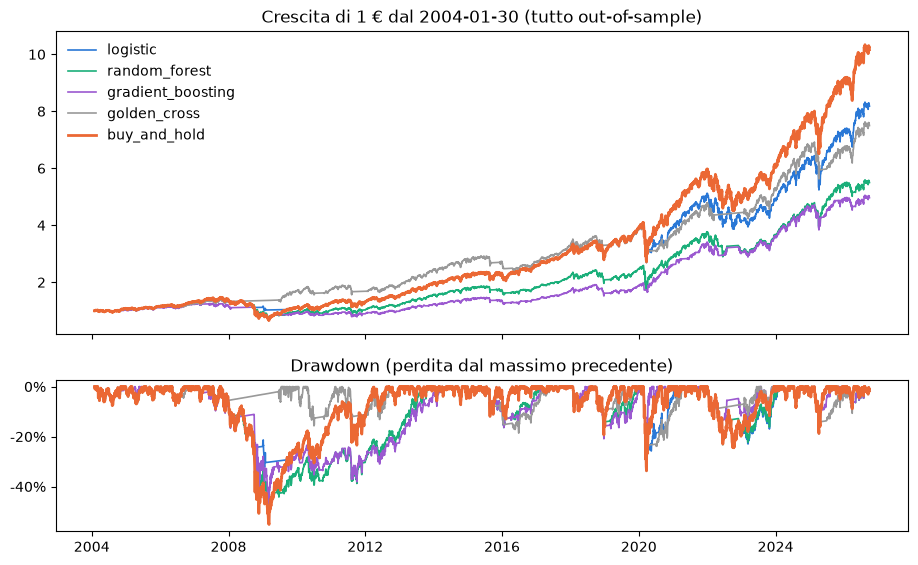

In [6]:
COLORS = {"logistic": "#2a78d6", "random_forest": "#1baf7a", "gradient_boosting": "#9b59d0",
          "golden_cross": "#999999", "buy_and_hold": "#eb6834"}
equity = (1 + net).cumprod()
dd = equity / equity.cummax() - 1
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[2, 1])
for name in net:
    width = 2.0 if name == "buy_and_hold" else 1.2
    top.plot(equity[name], color=COLORS[name], linewidth=width, label=name)
    bottom.plot(dd[name], color=COLORS[name], linewidth=width)
top.set_title(f"Crescita di 1 € dal {first_day.date()} (tutto out-of-sample)")
top.legend(loc="upper left", frameon=False)
bottom.set_title("Drawdown (perdita dal massimo precedente)")
bottom.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()

## 7. Cosa ha imparato la regressione logistica

Allenata su tutti i mesi: i pesi delle feature standardizzate. Positivo = quando la feature sale, il modello è più ottimista. Serve solo a **capire** il modello, non a giudicarlo (questi pesi hanno visto tutto il periodo).

In [7]:
final = models["logistic"]()
final.fit(features[target.notna()], target[target.notna()])
weights = pd.Series(final[-1].coef_[0], index=features.columns).sort_values()
print(weights.round(3).to_string())

ret_6m       -0.308
ret_3m       -0.110
vol_1m       -0.087
ret_1m       -0.012
vix          -0.006
ret_12m       0.064
dist_ma200    0.382


## Conclusione

**Nessuno dei tre modelli batte il buy & hold**, e i più potenti fanno peggio.

1. **Indovinare non basta.** Tutti e tre indovinano meno spesso (60–65%) del modello stupido che dice sempre "sale" (66,5%).
2. **Più potenza, risultati peggiori.** Regressione logistica: Sharpe 0,50, quasi uguale al buy & hold (0,51). Random forest e gradient boosting: 0,38 e 0,37. Con circa 400 esempi i modelli flessibili imparano rumore: è l'overfitting, visto dal vivo su dati mai visti.
3. **Nessuna differenza supera la prova della fortuna.** Tutti gli intervalli al 98,3% (Bonferroni, 3 tentativi) contengono lo zero.
4. **Il modello semplice ha riscoperto il trend.** Il peso più forte della logistica è `dist_ma200` (prezzo sopra la media a 200 giorni → più ottimista): è l'idea del golden cross, ritrovata da sola. Il golden cross, che sta in due righe, ha comunque Sharpe 0,54: il ML non ha aggiunto nulla rispetto a una regola semplice.
5. **Limiti.** Un solo asset (SPY, con survivorship bias), poche feature, solo dati di prezzo e VIX, impostazioni dei modelli fissate a priori e non ottimizzate (scelta voluta: ottimizzarle sarebbe un altro modo di provare tante volte).

**In una frase:** su un indice efficiente come SPY, con dati pubblici di prezzo, il machine learning non batte né il mercato né una regola semplice. Misurarlo onestamente è il risultato.